# Modeling Human Activity States Using Hidden Markov Models

This notebook builds a Gaussian Hidden Markov Model **from scratch with NumPy** to infer four activity
states (Still, Standing, Walking, Jumping) from smartphone accelerometer and gyroscope data recorded with
Sensor Logger.

**Pipeline:** raw Sensor Logger `.zip` exports → cleaned & resampled CSVs → windowing → time & frequency
features → Z-score normalisation → HMM (supervised initialisation + Baum–Welch) → Viterbi decoding →
evaluation on unseen recordings.

**Folder layout expected**
```
data/                 raw Sensor Logger zips, named <Activity>_<number>-<date>.zip
data/test/            unseen continuous test recordings (.zip) + test_labels.csv
dataset/              cleaned CSVs written by this notebook (one folder per activity)
figures/              plots saved for the report
```
Only `numpy`, `pandas` and `matplotlib` are used, so the whole notebook runs in seconds on a laptop.

In [1]:
import io
import re
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAW_DIR = Path("data")
TEST_DIR = RAW_DIR / "test"
CLEAN_DIR = Path("dataset")
FIG_DIR = Path("figures")
CLEAN_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)

TARGET_HZ = 50        # common sampling rate after harmonisation
WINDOW = 128          # samples per window  -> 2.56 s at 50 Hz
HOP = 64              # 50 % overlap        -> one observation every 1.28 s
TRIM_S = 0.5          # seconds removed at the start/end of each clip (tapping the phone)
MAX_S = 10.0          # cap clip length at 10 s
SEED = 42

# File-name prefix -> activity label ("Floor" recordings are the phone lying still on a flat surface)
ACTIVITY_MAP = {"standing": "Standing", "walking": "Walking", "jump": "Jumping",
                "jumping": "Jumping", "floor": "Still", "still": "Still"}
STATES = ["Still", "Standing", "Walking", "Jumping"]
K = len(STATES)
STATE_IDX = {s: i for i, s in enumerate(STATES)}
COLORS = ["#4C72B0", "#55A868", "#DD8452", "#C44E52"]

rng = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## 1. Data loading, cleaning and sampling-rate harmonisation

Sensor Logger records each sensor at its own rate (on our Pixel 3a: accelerometer ≈ 50 Hz, gyroscope ≈ 100 Hz).
To build one feature vector per time window, every sensor must share the same time axis, so each recording is
**resampled onto a common 50 Hz grid by linear interpolation** over the time span where all sensors overlap.
50 Hz was chosen because it is the lowest native rate (no up-sampling of the accelerometer) and its Nyquist
frequency (25 Hz) is well above the frequencies of human movement (< 20 Hz). The same code works for any phone:
whatever a member's native rates are, the output is always 50 Hz.

Cleaning steps: sort by timestamp and drop duplicates, trim 0.5 s at both ends (the tap to start/stop the
recording), and cap clips at 10 s.

In [2]:
UNITS = ("zero one two three four five six seven eight nine ten eleven twelve thirteen fourteen "
         "fifteen sixteen seventeen eighteen nineteen").split()
TENS = {"twenty": 20, "thirty": 30, "forty": 40, "fourty": 40, "fifty": 50}


def parse_name(path):
    """'Walking_thirty_one_-2026-10-28_15-57-34.zip' -> ('Walking', 31)."""
    m = re.match(r"([A-Za-z]+)_(.*?)-\d{4}-\d\d-\d\d_", path.name)
    activity = ACTIVITY_MAP[m.group(1).lower()]
    words = [w for w in re.split(r"[_\s]+", m.group(2).lower()) if w]
    if words and words[0].isdigit():
        return activity, int(words[0])
    return activity, sum(TENS.get(w, 0) + (UNITS.index(w) if w in UNITS else 0) for w in words)


def read_sensor(z, name):
    df = pd.read_csv(io.BytesIO(z.read(name)))
    return df.sort_values("seconds_elapsed").drop_duplicates("seconds_elapsed")


def load_recording(zip_path, trim=True):
    """Read one Sensor Logger zip and resample accelerometer, gyroscope and total acceleration to TARGET_HZ."""
    with zipfile.ZipFile(zip_path) as z:
        sensors = {"acc": read_sensor(z, "Accelerometer.csv"),        # linear acceleration (gravity removed)
                   "gyro": read_sensor(z, "Gyroscope.csv"),           # angular velocity
                   "tacc": read_sensor(z, "TotalAcceleration.csv")}   # acceleration incl. gravity
        meta = pd.read_csv(io.BytesIO(z.read("Metadata.csv"))).iloc[0]
    native_hz = {k: 1 / np.median(np.diff(df["seconds_elapsed"])) for k, df in sensors.items()}

    s0 = max(df["seconds_elapsed"].iloc[0] for df in sensors.values())
    s1 = min(df["seconds_elapsed"].iloc[-1] for df in sensors.values())
    if trim:
        s0, s1 = s0 + TRIM_S, s1 - TRIM_S
        s1 = min(s1, s0 + MAX_S)
    sec = np.arange(s0, s1, 1 / TARGET_HZ)

    out = {"timestamp_ns": (int(meta["recording epoch time"]) * 10**6 + np.round(sec * 1e9)).astype("int64"),
           "seconds_elapsed": sec}
    for prefix, df in sensors.items():
        for ax in "xyz":
            out[f"{prefix}_{ax}"] = np.interp(sec, df["seconds_elapsed"], df[ax])
    return pd.DataFrame(out), native_hz, meta["device name"]


records = []
for zp in sorted(RAW_DIR.glob("*.zip")):
    activity, num = parse_name(zp)
    df, native_hz, device = load_recording(zp)
    out_path = CLEAN_DIR / activity.lower() / f"{activity.lower()}_{num:02d}.csv"
    out_path.parent.mkdir(parents=True, exist_ok=True)
    df.insert(0, "activity", activity)
    df.to_csv(out_path, index=False)
    records.append({"file": out_path.name, "path": out_path, "activity": activity, "number": num,
                    "device": device, "acc_hz": native_hz["acc"], "gyro_hz": native_hz["gyro"],
                    "duration_s": df["seconds_elapsed"].iloc[-1] - df["seconds_elapsed"].iloc[0],
                    "source_zip": zp.name})

catalog = pd.DataFrame(records)
print(f"Cleaned {len(catalog)} recordings -> {CLEAN_DIR}/<activity>/\n")

summary = catalog.groupby("activity").agg(files=("file", "count"), total_s=("duration_s", "sum"),
                                          min_s=("duration_s", "min"), max_s=("duration_s", "max"))
summary["missing_numbers (1-50)"] = [sorted(set(range(1, 51)) - set(catalog.loc[catalog.activity == a, "number"]))
                                     for a in summary.index]
display(summary.round(1))

print("Native sampling rate per device (median Hz) -> all resampled to", TARGET_HZ, "Hz")
display(catalog.groupby("device")[["acc_hz", "gyro_hz"]].median().round(1))

Cleaned 200 recordings -> dataset/<activity>/



,files,total_s,min_s,max_s,missing_numbers (1-50)
activity,,,,,
Jumping,50,357.7,4.6,10.0,[]
Standing,50,293.8,4.5,7.8,[]
Still,50,346.2,5.4,8.8,[]
Walking,50,398.2,5.7,10.0,[]


Native sampling rate per device (median Hz) -> all resampled to 50 Hz


,acc_hz,gyro_hz
device,,
Pixel 3a,50.4,100.8


### Sample of the cleaned signals
One recording per activity: magnitude of linear acceleration and of angular velocity.

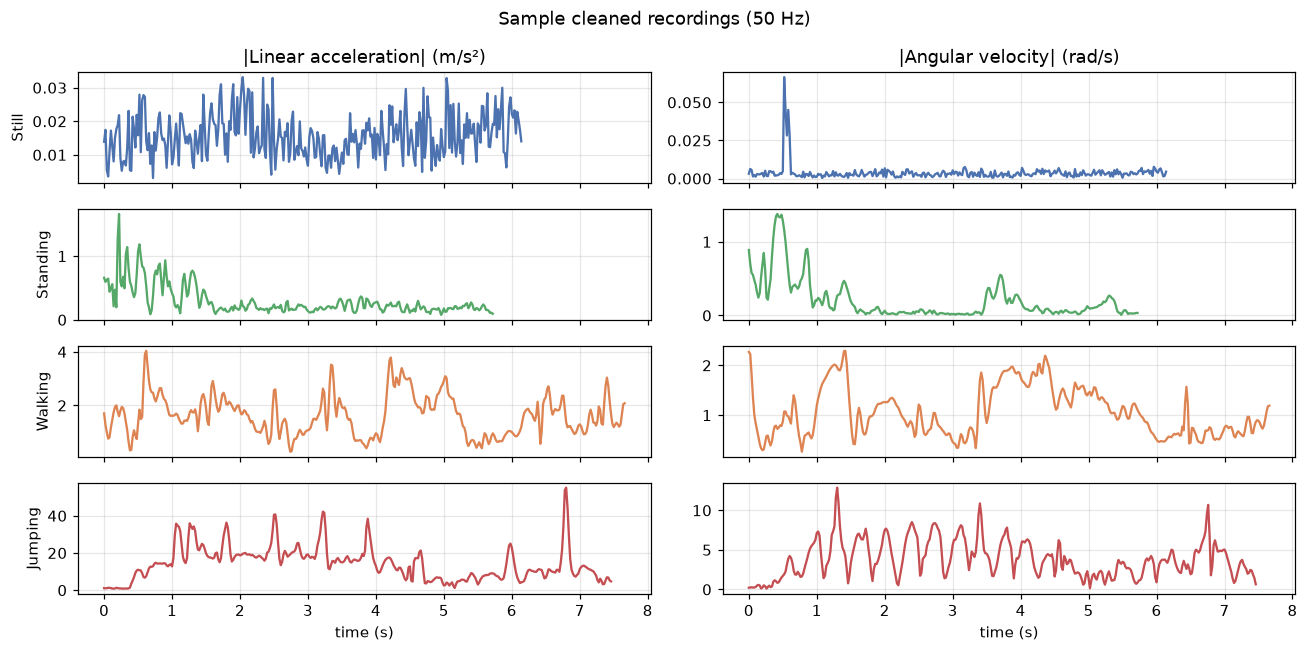

In [3]:
fig, axes = plt.subplots(K, 2, figsize=(12, 6), sharex=True)
for i, act in enumerate(STATES):
    df = pd.read_csv(catalog[catalog.activity == act].iloc[0]["path"])
    t = df["seconds_elapsed"] - df["seconds_elapsed"].iloc[0]
    axes[i, 0].plot(t, np.linalg.norm(df[["acc_x", "acc_y", "acc_z"]], axis=1), color=COLORS[i])
    axes[i, 1].plot(t, np.linalg.norm(df[["gyro_x", "gyro_y", "gyro_z"]], axis=1), color=COLORS[i])
    axes[i, 0].set_ylabel(act)
axes[0, 0].set_title("|Linear acceleration| (m/s²)")
axes[0, 1].set_title("|Angular velocity| (rad/s)")
axes[-1, 0].set_xlabel("time (s)")
axes[-1, 1].set_xlabel("time (s)")
fig.suptitle("Sample cleaned recordings (50 Hz)")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig1_sample_signals.png")
plt.show()

## 2. Windowing and feature extraction

**Window size logic.** At 50 Hz a window of **128 samples = 2.56 s** with **50 % overlap (hop 64 = 1.28 s)**.
2.56 s covers at least 2–4 full walking steps or jumps (≈ 1.5–2.5 Hz), so periodic patterns are visible in each
window, and gives an FFT frequency resolution of 50/128 ≈ 0.39 Hz – fine enough to separate step and jump
rhythms. A power-of-two length keeps the FFT efficient, and a 5–10 s clip still yields 3–6 observations.

| Feature | Domain | Why it separates the activities |
|---|---|---|
| `acc_std` – std of linear-acc magnitude | time | near 0 when still, moderate walking, very high jumping |
| `acc_sma` – signal magnitude area of linear acc | time | overall movement intensity |
| `gyro_std` – std of angular-velocity magnitude | time | body sway/rotation: standing > still, walking has strong rotation |
| `gyro_sma` – signal magnitude area of gyro | time | total rotation energy |
| `acc_corr_yz` – correlation between acc y and z axes | time | coordinated vertical/forward motion in gait and jumps |
| `tilt_z` – gravity component on z / ‖g‖ (mean) | time | phone orientation relative to gravity: stays ≈ 1 when the phone is held/lying flat (Still, Standing) and drops when it swings and tilts (Walking, Jumping) |
| `dom_freq` – dominant FFT frequency of acc magnitude | frequency | step/jump cadence; random for static states |
| `spec_energy` – FFT spectral energy | frequency | energy of the movement |
| `spec_entropy` – normalised spectral entropy | frequency | periodic motion (low entropy) vs noise (high entropy) |

**Drift removal.** Android's *linear* acceleration is computed by subtracting an estimated gravity vector;
after the phone is moved quickly (e.g. put down) that estimate lags for several seconds and leaves a slowly
decaying offset in the signal although the phone is motionless. Each accelerometer axis is therefore
**linearly detrended inside every window** before the features are computed, so they measure vibration and
movement rather than offsets.

Intensity features span several orders of magnitude (≈ 10⁻⁴ still vs 10² jumping), so they are **log-transformed**
before normalisation, which makes their distribution closer to the Gaussian assumed by the emission model.

In [4]:
FEATURES = ["acc_std", "acc_sma", "gyro_std", "gyro_sma", "acc_corr_yz", "tilt_z",
            "dom_freq", "spec_energy", "spec_entropy"]
LOG_FEATURES = ["acc_std", "acc_sma", "gyro_std", "gyro_sma", "spec_energy"]


def detrend(x):
    """Remove the best-fit straight line from each column (slow offsets/drift inside the window)."""
    t = np.arange(len(x)) - (len(x) - 1) / 2
    slope = (t @ (x - x.mean(axis=0))) / (t @ t)
    return x - x.mean(axis=0) - np.outer(t, slope)


def window_features(w):
    acc = detrend(w[["acc_x", "acc_y", "acc_z"]].to_numpy())
    gyr = w[["gyro_x", "gyro_y", "gyro_z"]].to_numpy()
    tacc = w[["tacc_x", "tacc_y", "tacc_z"]].to_numpy()
    acc_mag = np.linalg.norm(acc, axis=1)
    gyr_mag = np.linalg.norm(gyr, axis=1)

    f = {"acc_std": acc_mag.std(),
         "acc_sma": np.abs(acc).sum(axis=1).mean(),
         "gyro_std": gyr_mag.std(),
         "gyro_sma": np.abs(gyr).sum(axis=1).mean()}
    sy, sz = acc[:, 1].std(), acc[:, 2].std()
    f["acc_corr_yz"] = np.corrcoef(acc[:, 1], acc[:, 2])[0, 1] if sy > 1e-9 and sz > 1e-9 else 0.0
    g = tacc.mean(axis=0)
    f["tilt_z"] = g[2] / np.linalg.norm(g)

    x = (acc_mag - acc_mag.mean()) * np.hanning(len(acc_mag))
    power = np.abs(np.fft.rfft(x)) ** 2
    freqs = np.fft.rfftfreq(len(x), 1 / TARGET_HZ)
    power[0] = 0.0
    f["dom_freq"] = freqs[np.argmax(power)]
    f["spec_energy"] = power.sum() / len(x)
    p = power / power.sum() if power.sum() > 0 else np.full_like(power, 1 / len(power))
    f["spec_entropy"] = -(p * np.log2(p + 1e-12)).sum() / np.log2(len(p))
    return f


def recording_to_windows(df):
    """Slide a WINDOW-sample window with HOP step; return feature matrix and window centre times."""
    feats, times = [], []
    for start in range(0, len(df) - WINDOW + 1, HOP):
        w = df.iloc[start:start + WINDOW]
        f = window_features(w)
        feats.append([np.log10(f[k] + 1e-8) if k in LOG_FEATURES else f[k] for k in FEATURES])
        times.append(w["seconds_elapsed"].iloc[WINDOW // 2])
    return np.array(feats), np.array(times)


clips = []
for _, row in catalog.iterrows():
    X, t = recording_to_windows(pd.read_csv(row["path"]))
    clips.append({"file": row["file"], "activity": row["activity"], "X": X, "t": t,
                  "y": np.full(len(X), STATE_IDX[row["activity"]])})

all_X = np.vstack([c["X"] for c in clips])
all_y = np.concatenate([c["y"] for c in clips])
print(f"{len(all_X)} windows x {all_X.shape[1]} features")
display(pd.DataFrame(all_X, columns=FEATURES).assign(activity=[STATES[i] for i in all_y])
        .groupby("activity")[FEATURES].mean().loc[STATES].round(3))

794 windows x 9 features


,acc_std,acc_sma,gyro_std,gyro_sma,acc_corr_yz,tilt_z,dom_freq,spec_energy,spec_entropy
activity,,,,,,,,,
Still,-2.100,-1.668,-2.421,-2.251,0.084,1.000,5.643,-2.942,0.870
Standing,-0.880,-0.537,-1.054,-0.790,-0.288,0.990,1.309,-0.536,0.673
Walking,-0.107,0.404,-0.295,0.168,0.007,0.966,1.348,1.136,0.652
Jumping,0.976,1.353,0.288,0.746,0.282,0.775,3.224,3.299,0.553


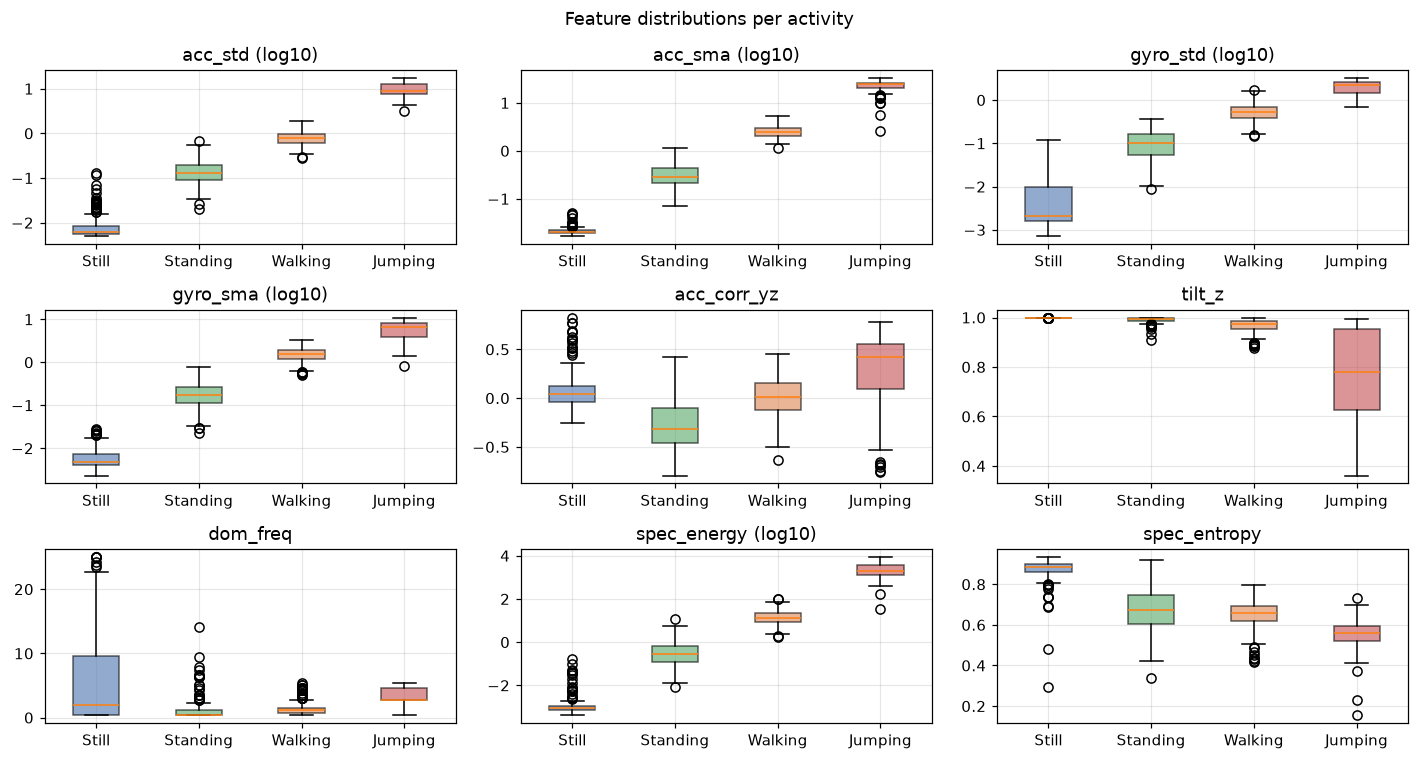

In [5]:
fig, axes = plt.subplots(3, 3, figsize=(13, 7))
for ax, j in zip(axes.ravel(), range(len(FEATURES))):
    data = [all_X[all_y == k, j] for k in range(K)]
    bp = ax.boxplot(data, patch_artist=True)
    ax.set_xticks(range(1, K + 1), STATES)
    for patch, c in zip(bp["boxes"], COLORS):
        patch.set_facecolor(c)
        patch.set_alpha(0.6)
    ax.set_title(FEATURES[j] + (" (log10)" if FEATURES[j] in LOG_FEATURES else ""))
fig.suptitle("Feature distributions per activity")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig2_feature_distributions.png")
plt.show()

## 3. Train / validation split, normalisation and training sequences

* **Split by recording, not by window** (80 % train / 20 % validation per activity), so overlapping windows of
  the same clip never end up on both sides.
* **Z-score normalisation** `(x − μ) / σ` with μ, σ computed on the **training set only** and re-used for
  validation and test data. Z-scoring puts all features on the same scale so that no feature (e.g. spectral
  energy) dominates the Gaussian covariance, and it is the natural choice for Gaussian emissions (unlike min–max,
  it is not driven by a single extreme jump window).
* **Training sequences.** Each clip contains a single activity, so the clips are chained into longer sequences
  following realistic transitions (e.g. Still → Standing → Walking → Jumping → Standing → Still). This gives
  Baum–Welch real activity changes from which to learn the transition matrix. Physically implausible jumps
  (e.g. Still → Jumping without picking the phone up) are not generated.

In [6]:
ALLOWED_NEXT = {"Still": ["Standing"],
                "Standing": ["Walking", "Jumping", "Still"],
                "Walking": ["Standing", "Jumping"],
                "Jumping": ["Standing", "Walking"]}

train_clips, val_clips = [], []
for act in STATES:
    group = [c for c in clips if c["activity"] == act]
    order = rng.permutation(len(group))
    n_val = max(1, round(0.2 * len(group)))
    val_clips += [group[i] for i in order[:n_val]]
    train_clips += [group[i] for i in order[n_val:]]

mu = np.vstack([c["X"] for c in train_clips]).mean(axis=0)
sigma = np.vstack([c["X"] for c in train_clips]).std(axis=0) + 1e-8
normalise = lambda X: (X - mu) / sigma


def build_chains(clip_list, rng, max_clips=12):
    """Chain single-activity clips into sessions that start Still/Standing and follow ALLOWED_NEXT.

    When no allowed next activity has clips left, any remaining activity is used so that no clip is wasted
    (these rare fallback transitions are smoothed by the Laplace prior and the transition floor).
    """
    pools = {a: [c for c in clip_list if c["activity"] == a] for a in STATES}
    for a in pools:
        pools[a] = [pools[a][i] for i in rng.permutation(len(pools[a]))]
    chains = []
    while any(pools.values()):
        starts = [a for a in ("Still", "Standing") if pools[a]] or [a for a in STATES if pools[a]]
        current = rng.choice(starts)
        seq = []
        while current is not None and len(seq) < max_clips:
            seq.append(pools[current].pop())
            options = ([a for a in ALLOWED_NEXT[current] if pools[a]]
                       or [a for a in STATES if pools[a] and a != current])
            current = rng.choice(options) if options else None
        chains.append({"X": normalise(np.vstack([c["X"] for c in seq])),
                       "y": np.concatenate([c["y"] for c in seq]),
                       "t": np.arange(sum(len(c["X"]) for c in seq)) * HOP / TARGET_HZ})
    return chains


train_seqs = build_chains(train_clips, rng)
val_seqs = build_chains(val_clips, rng)
print(f"train: {len(train_clips)} clips -> {len(train_seqs)} sequences, "
      f"{sum(len(s['y']) for s in train_seqs)} windows")
print(f"validation: {len(val_clips)} clips -> {len(val_seqs)} sequences, "
      f"{sum(len(s['y']) for s in val_seqs)} windows")

train: 160 clips -> 28 sequences, 637 windows
validation: 40 clips -> 9 sequences, 157 windows


## 4. HMM components and algorithms

| Element | Definition in this project |
|---|---|
| Hidden states **Z** | Still, Standing, Walking, Jumping |
| Observations **X** | 9-dimensional Z-scored feature vector of each 2.56 s window |
| Transitions **A** | `A[i, j] = P(z_t = j | z_{t-1} = i)` between consecutive windows |
| Emissions **B** | multivariate Gaussian `N(x | μ_k, Σ_k)` per state (full covariance) |
| Initial probs **π** | `π_k = P(z_1 = k)` |

**Algorithms.**
* **Baum–Welch (EM, forward–backward)** estimates π, A, μ and Σ by maximising the data log-likelihood. We
  initialise it from the labelled windows (class means/covariances and transition counts), which fixes which
  hidden state corresponds to which activity, then let EM refine the parameters. Training stops when the
  log-likelihood improves by less than ε = 1e-3 (max 200 iterations as a safety net).
* **Viterbi** finds the single most likely state sequence, which is exactly what the evaluation needs: every
  window gets one activity label, which is compared to the ground truth to compute sensitivity, specificity and
  accuracy. Viterbi uses A to enforce temporal consistency, which removes isolated misclassified windows
  that a per-window classifier would make, improving all three metrics.
* The **forward algorithm** gives the sequence log-likelihood used for the convergence check.

All computations are done in **log space** (log-sum-exp) to avoid numerical underflow on long sequences.

In [7]:
def logsumexp(a, axis):
    m = np.max(a, axis=axis, keepdims=True)
    m = np.where(np.isfinite(m), m, 0.0)
    return np.squeeze(m, axis=axis) + np.log(np.sum(np.exp(a - m), axis=axis))


class GaussianHMM:
    """Hidden Markov Model with full-covariance Gaussian emissions, implemented with NumPy."""

    def __init__(self, n_states, reg=1e-2, a_floor=1e-4):
        self.K = n_states
        self.reg = reg            # added to covariance diagonals to keep them invertible
        self.a_floor = a_floor    # minimum transition/initial probability (avoids impossible events)
        self.history = []

    # ---------- initialisation ----------
    def init_supervised(self, sequences):
        """Estimate pi, A, means and covariances directly from labelled sequences."""
        X = np.vstack([s["X"] for s in sequences])
        y = np.concatenate([s["y"] for s in sequences])
        D = X.shape[1]
        self.means = np.array([X[y == k].mean(axis=0) for k in range(self.K)])
        self.covs = np.array([np.cov(X[y == k].T) + self.reg * np.eye(D) for k in range(self.K)])
        counts = np.ones((self.K, self.K))                      # Laplace smoothing
        starts = np.ones(self.K)
        for s in sequences:
            starts[s["y"][0]] += 1
            np.add.at(counts, (s["y"][:-1], s["y"][1:]), 1)
        self.pi = starts / starts.sum()
        self.A = counts / counts.sum(axis=1, keepdims=True)
        return self

    # ---------- core probabilities ----------
    def log_emission(self, X):
        """log N(x_t | mu_k, Sigma_k) for every window t and state k -> (T, K)."""
        T, D = X.shape
        out = np.empty((T, self.K))
        for k in range(self.K):
            L = np.linalg.cholesky(self.covs[k])
            z = np.linalg.solve(L, (X - self.means[k]).T)
            out[:, k] = -0.5 * (np.sum(z ** 2, axis=0) + D * np.log(2 * np.pi)) - np.log(np.diag(L)).sum()
        return out

    def forward(self, logB):
        T = len(logB)
        log_alpha = np.empty((T, self.K))
        log_alpha[0] = np.log(self.pi) + logB[0]
        logA = np.log(self.A)
        for t in range(1, T):
            log_alpha[t] = logsumexp(log_alpha[t - 1][:, None] + logA, axis=0) + logB[t]
        return log_alpha

    def backward(self, logB):
        T = len(logB)
        log_beta = np.zeros((T, self.K))
        logA = np.log(self.A)
        for t in range(T - 2, -1, -1):
            log_beta[t] = logsumexp(logA + (logB[t + 1] + log_beta[t + 1])[None, :], axis=1)
        return log_beta

    def score(self, X):
        """Log-likelihood log P(X | model) from the forward algorithm."""
        return logsumexp(self.forward(self.log_emission(X))[-1], axis=0)

    # ---------- Baum–Welch ----------
    def fit(self, sequences, tol=1e-3, max_iter=200, verbose=True):
        D = sequences[0]["X"].shape[1]
        logA = None
        for it in range(max_iter):
            logA = np.log(self.A)
            pi_acc = np.zeros(self.K)
            A_acc = np.zeros((self.K, self.K))
            g_sum = np.zeros(self.K)
            x_sum = np.zeros((self.K, D))
            xx_sum = np.zeros((self.K, D, D))
            total_ll = 0.0

            # E-step: forward-backward on every sequence
            for s in sequences:
                X = s["X"]
                logB = self.log_emission(X)
                la, lb = self.forward(logB), self.backward(logB)
                ll = logsumexp(la[-1], axis=0)
                total_ll += ll
                gamma = np.exp(la + lb - ll)                                   # (T, K)
                xi = np.exp(la[:-1, :, None] + logA[None] + (logB[1:] + lb[1:])[:, None, :] - ll)
                pi_acc += gamma[0]
                A_acc += xi.sum(axis=0)
                g_sum += gamma.sum(axis=0)
                x_sum += gamma.T @ X
                xx_sum += np.einsum("tk,ti,tj->kij", gamma, X, X)

            self.history.append(total_ll)
            converged = it > 0 and abs(self.history[-1] - self.history[-2]) < tol

            # M-step
            pi = np.maximum(pi_acc / pi_acc.sum(), self.a_floor)
            self.pi = pi / pi.sum()
            A = np.maximum(A_acc / A_acc.sum(axis=1, keepdims=True), self.a_floor)
            self.A = A / A.sum(axis=1, keepdims=True)
            self.means = x_sum / g_sum[:, None]
            self.covs = (xx_sum / g_sum[:, None, None]
                         - np.einsum("ki,kj->kij", self.means, self.means)
                         + self.reg * np.eye(D))

            if verbose and (it % 10 == 0 or converged):
                print(f"iter {it:3d}   log-likelihood = {total_ll:12.3f}")
            if converged:
                print(f"Converged after {it} iterations (log-likelihood change < {tol})")
                break
        else:
            print(f"Stopped at max_iter={max_iter} without reaching tol")
        return self

    # ---------- decoding ----------
    def viterbi(self, X):
        """Most likely hidden-state path for observation sequence X."""
        logB = self.log_emission(X)
        T = len(X)
        logA = np.log(self.A)
        delta = np.empty((T, self.K))
        psi = np.zeros((T, self.K), dtype=int)
        delta[0] = np.log(self.pi) + logB[0]
        for t in range(1, T):
            scores = delta[t - 1][:, None] + logA        # (from, to)
            psi[t] = scores.argmax(axis=0)
            delta[t] = scores.max(axis=0) + logB[t]
        path = np.empty(T, dtype=int)
        path[-1] = delta[-1].argmax()
        for t in range(T - 2, -1, -1):
            path[t] = psi[t + 1][path[t + 1]]
        return path

    def predict_independent(self, X):
        """Per-window classification using emissions only (no temporal model) – baseline."""
        return self.log_emission(X).argmax(axis=1)

## 5. Training

iter   0   log-likelihood =      614.971


iter   7   log-likelihood =      736.799
Converged after 7 iterations (log-likelihood change < 0.001)


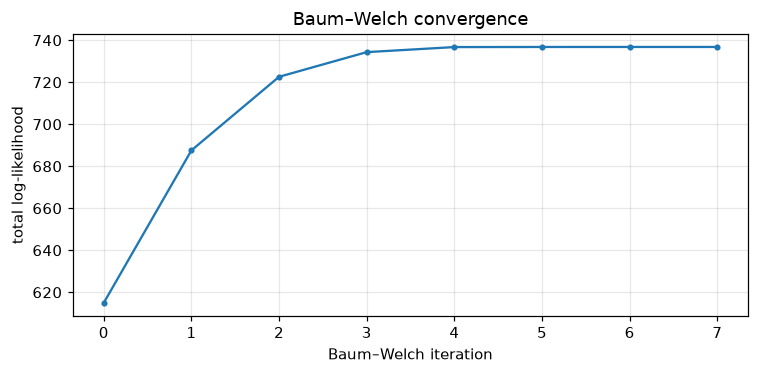

In [8]:
init_model = GaussianHMM(K).init_supervised(train_seqs)

model = GaussianHMM(K).init_supervised(train_seqs)
model.fit(train_seqs, tol=1e-3, max_iter=200)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(model.history, marker="o", ms=3)
ax.set_xlabel("Baum–Welch iteration")
ax.set_ylabel("total log-likelihood")
ax.set_title("Baum–Welch convergence")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig3_convergence.png")
plt.show()

### Learned transition and emission parameters

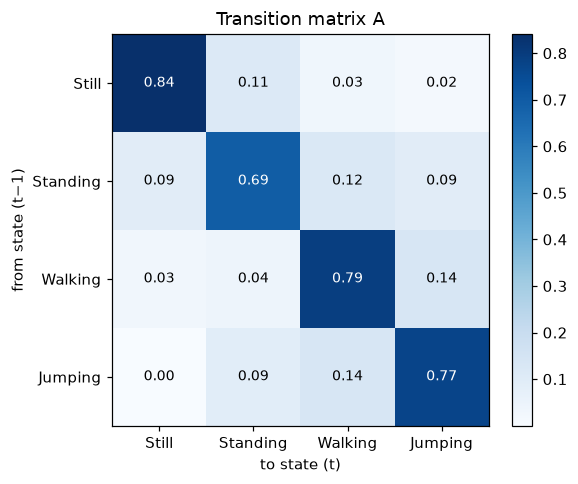

Initial state probabilities π: {'Still': 0.821, 'Standing': 0.179, 'Walking': 0.0, 'Jumping': 0.0}
Expected stay per state (seconds) = HOP/fs / (1 − A_ii): {'Still': 8.0, 'Standing': 4.2, 'Walking': 6.2, 'Jumping': 5.7}


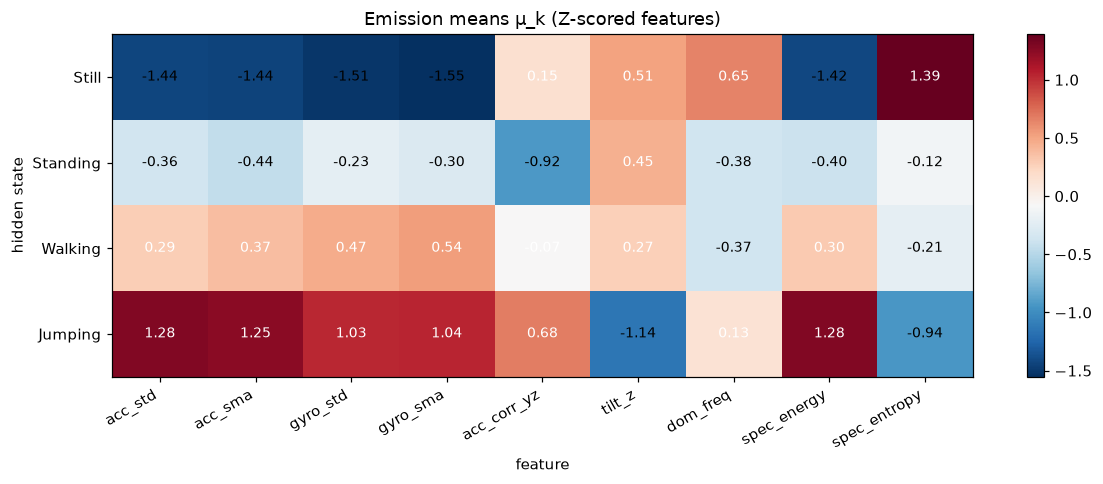

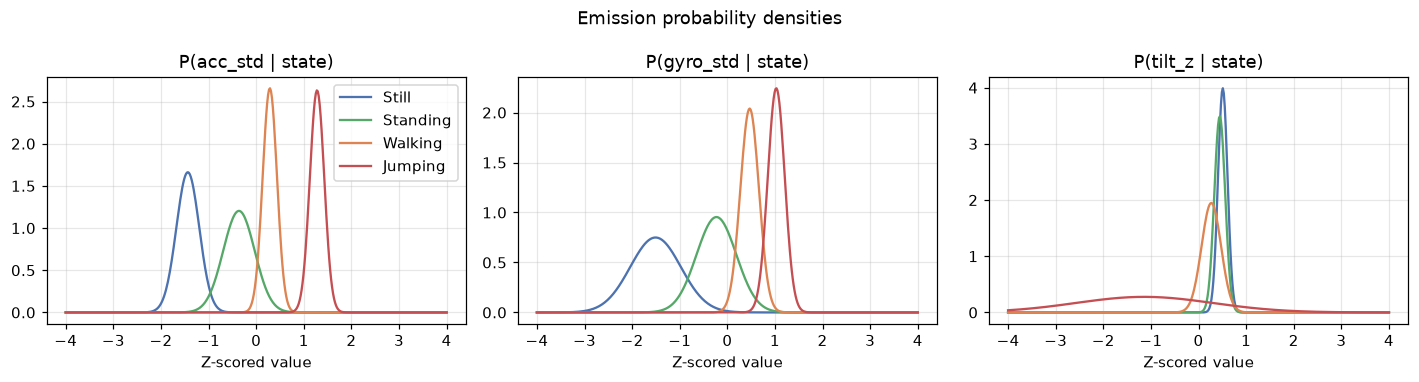

In [9]:
def plot_matrix(M, title, fname, labels_x=STATES, labels_y=STATES, fmt="{:.2f}", cmap="Blues",
                xlabel="", ylabel=""):
    fig, ax = plt.subplots(figsize=(5.5 if len(labels_x) <= 4 else 11, 4.5))
    im = ax.imshow(M, cmap=cmap, aspect="auto")
    ax.set_xticks(range(len(labels_x)), labels_x, rotation=30 if len(labels_x) > 4 else 0, ha="right" if len(labels_x) > 4 else "center")
    ax.set_yticks(range(len(labels_y)), labels_y)
    ax.grid(False)
    thresh = (np.nanmax(M) + np.nanmin(M)) / 2
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, fmt.format(M[i, j]), ha="center", va="center",
                    color="white" if M[i, j] > thresh else "black", fontsize=9)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    fig.colorbar(im, ax=ax)
    fig.tight_layout()
    fig.savefig(FIG_DIR / fname)
    plt.show()


plot_matrix(model.A, "Transition matrix A", "fig4_transition_matrix.png",
            xlabel="to state (t)", ylabel="from state (t−1)")
print("Initial state probabilities π:", {s: round(float(p), 3) for s, p in zip(STATES, model.pi)})
print("Expected stay per state (seconds) = HOP/fs / (1 − A_ii):",
      {s: round(float(HOP / TARGET_HZ / (1 - model.A[k, k])), 1) for k, s in enumerate(STATES)})

plot_matrix(model.means, "Emission means μ_k (Z-scored features)", "fig5_emission_means.png",
            labels_x=FEATURES, cmap="RdBu_r", xlabel="feature", ylabel="hidden state")

# Emission densities for three key features (marginal Gaussians of each state)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, feat in zip(axes, ["acc_std", "gyro_std", "tilt_z"]):
    j = FEATURES.index(feat)
    xs = np.linspace(-4, 4, 400)
    for k in range(K):
        m, sd = model.means[k, j], np.sqrt(model.covs[k, j, j])
        ax.plot(xs, np.exp(-0.5 * ((xs - m) / sd) ** 2) / (sd * np.sqrt(2 * np.pi)), color=COLORS[k], label=STATES[k])
    ax.set_title(f"P({feat} | state)")
    ax.set_xlabel("Z-scored value")
axes[0].legend()
fig.suptitle("Emission probability densities")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig6_emission_densities.png")
plt.show()

## 6. Evaluation helpers

In [10]:
def evaluate(y_true, y_pred):
    mask = y_true >= 0                      # -1 = unlabelled transition windows (excluded)
    y_true, y_pred = y_true[mask], y_pred[mask]
    cm = np.zeros((K, K), dtype=int)
    np.add.at(cm, (y_true, y_pred), 1)
    N = cm.sum()
    rows = []
    for k in range(K):
        tp = cm[k, k]
        fn = cm[k].sum() - tp
        fp = cm[:, k].sum() - tp
        tn = N - tp - fn - fp
        rows.append({"State (Activity)": STATES[k], "Number of Samples": int(cm[k].sum()),
                     "Sensitivity": tp / (tp + fn) if tp + fn else np.nan,
                     "Specificity": tn / (tn + fp) if tn + fp else np.nan,
                     "Accuracy (TP+TN)/N": (tp + tn) / N})
    table = pd.DataFrame(rows)
    return table, cm, np.trace(cm) / N


def decode_all(m, seqs, method="viterbi"):
    f = m.viterbi if method == "viterbi" else m.predict_independent
    return np.concatenate([f(s["X"]) for s in seqs]), np.concatenate([s["y"] for s in seqs])


comparison = []
for name, m, method in [("Emissions only (no HMM)", model, "independent"),
                        ("HMM supervised init + Viterbi", init_model, "viterbi"),
                        ("HMM after Baum–Welch + Viterbi", model, "viterbi")]:
    yp, yt = decode_all(m, val_seqs, method)
    comparison.append({"model": name, "validation accuracy": evaluate(yt, yp)[2]})
display(pd.DataFrame(comparison).round(3))

,model,validation accuracy
0,Emissions only (no HMM),0.987
1,HMM supervised init + Viterbi,1.000
2,HMM after Baum–Welch + Viterbi,1.000


## 7. Evaluation on unseen data

Unseen test recordings go in `data/test/` (Sensor Logger zips) together with `data/test/test_labels.csv`:
```
file,start_s,end_s,activity
Test_one-2026-10-30_10-00-00.zip,0,10,Standing
Test_one-2026-10-30_10-00-00.zip,10,20,Walking
...
```
`start_s`/`end_s` are seconds from the start of the recording. Each window is labelled with the activity at its
centre; windows whose centre falls in a gap between labelled segments (e.g. while putting the phone down) are
decoded but excluded from the metrics. If no test files are present yet, the held-out validation sequences are
used so the notebook still runs end to end.

Test_one-2026-10-29_14-00-08.zip: 46 windows, device Pixel 3a, native acc 50 Hz / gyro 101 Hz


Test_two-2026-10-29_14-04-43.zip: 45 windows, device Pixel 3a, native acc 50 Hz / gyro 101 Hz

Results on unseen test recordings  –  overall accuracy = 0.957
Emissions-only baseline (no temporal model) accuracy = 0.942


,State (Activity),Number of Samples,Sensitivity,Specificity,Accuracy (TP+TN)/N
0,Still,18,0.944,1.00,0.986
1,Standing,26,1.000,0.93,0.957
2,Walking,12,0.917,1.00,0.986
3,Jumping,13,0.923,1.00,0.986


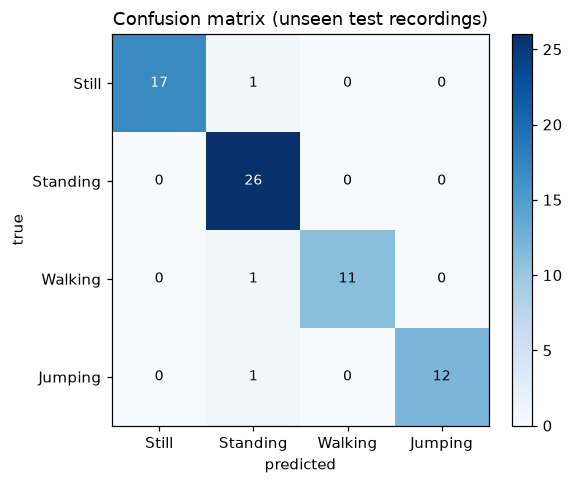

In [11]:
label_file = TEST_DIR / "test_labels.csv"
test_zips = sorted(TEST_DIR.glob("*.zip")) if TEST_DIR.exists() else []

if test_zips and label_file.exists():
    labels = pd.read_csv(label_file)
    test_seqs = []
    (CLEAN_DIR / "test").mkdir(exist_ok=True)
    for zp in test_zips:
        df, native_hz, device = load_recording(zp, trim=False)
        df.to_csv(CLEAN_DIR / "test" / (zp.stem + ".csv"), index=False)
        X, t = recording_to_windows(df)
        t = t - df["seconds_elapsed"].iloc[0]
        y = np.full(len(t), -1)
        for _, seg in labels[labels.file == zp.name].iterrows():
            y[(t >= seg.start_s) & (t < seg.end_s)] = STATE_IDX[seg.activity]
        test_seqs.append({"name": zp.stem, "X": normalise(X), "y": y, "t": t})
        print(f"{zp.name}: {len(t)} windows, device {device}, native acc {native_hz['acc']:.0f} Hz / "
              f"gyro {native_hz['gyro']:.0f} Hz")
    TEST_SOURCE = "unseen test recordings"
else:
    print("No files in data/test/ yet -> evaluating on held-out validation sequences instead.")
    test_seqs = [dict(s, name=f"validation sequence {i + 1}") for i, s in enumerate(val_seqs)]
    TEST_SOURCE = "held-out validation sequences"

y_pred, y_true = decode_all(model, test_seqs)
table, cm, overall_acc = evaluate(y_true, y_pred)
print(f"\nResults on {TEST_SOURCE}  –  overall accuracy = {overall_acc:.3f}")
yp_ind, _ = decode_all(model, test_seqs, "independent")
print(f"Emissions-only baseline (no temporal model) accuracy = {evaluate(y_true, yp_ind)[2]:.3f}")
display(table.round(3))

plot_matrix(cm, f"Confusion matrix ({TEST_SOURCE})", "fig7_confusion_matrix.png", fmt="{:d}",
            xlabel="predicted", ylabel="true")

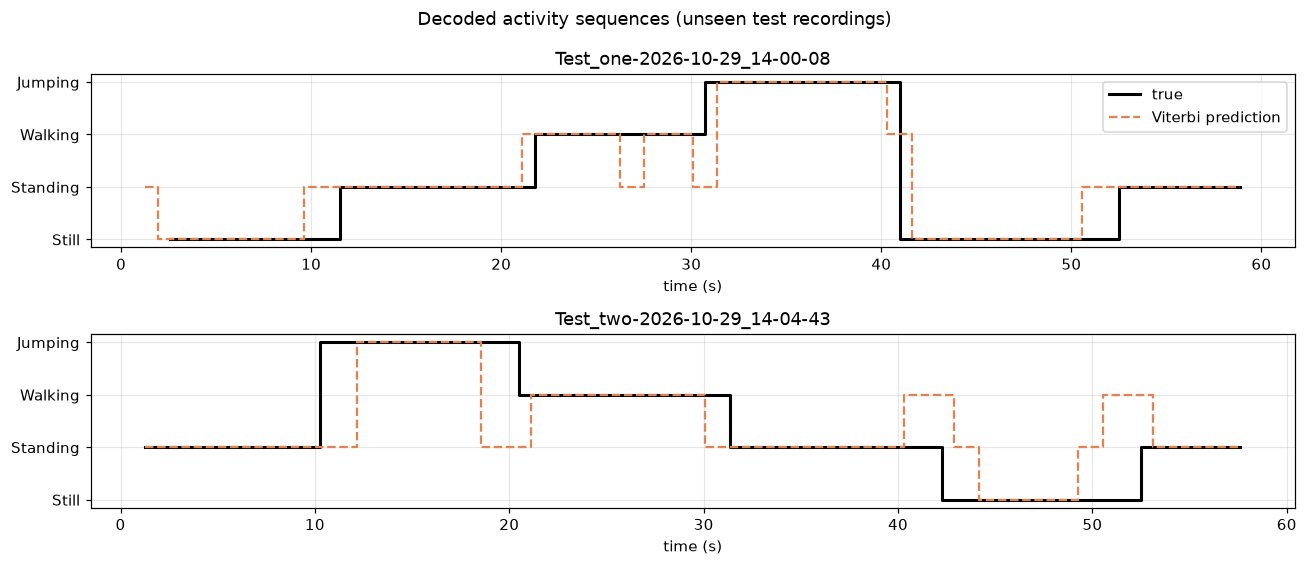

In [12]:
fig, axes = plt.subplots(len(test_seqs), 1, figsize=(12, 2.6 * len(test_seqs)), squeeze=False)
for ax, s in zip(axes[:, 0], test_seqs):
    pred = model.viterbi(s["X"])
    valid = s["y"] >= 0
    ax.step(s["t"][valid], s["y"][valid], where="mid", color="black", lw=2, label="true")
    ax.step(s["t"], pred, where="mid", color="#DD8452", lw=1.5, ls="--", label="Viterbi prediction")
    ax.set_yticks(range(K), STATES)
    ax.set_title(s["name"])
    ax.set_xlabel("time (s)")
axes[0, 0].legend(loc="upper right")
fig.suptitle(f"Decoded activity sequences ({TEST_SOURCE})")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig8_decoded_sequences.png")
plt.show()